In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "src" / "common.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.common import PERIODS

PERIOD = "1990-2004"
START, END = PERIODS[PERIOD]
RESULTS = ROOT / "periods" / PERIOD / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

## Data

In [2]:
raw = pd.read_csv(ROOT / "data" / "raw" / "2026-09-MD.csv")
tcodes = pd.to_numeric(raw.iloc[0, 1:]).astype(int)

raw_panel = raw.iloc[1:].copy()
raw_panel.index = pd.to_datetime(raw_panel["sasdate"], format="%m/%d/%Y")
raw_panel = raw_panel.drop(columns="sasdate").apply(pd.to_numeric, errors="coerce")

def transform(s, c):
    with np.errstate(all="ignore"):
        if c == 1: return s
        if c == 2: return s.diff()
        if c == 3: return s.diff().diff()
        if c == 4: return np.log(s)
        if c == 5: return np.log(s).diff()
        if c == 6: return np.log(s).diff().diff()
        if c == 7: return (s / s.shift(1) - 1).diff()

# no outlier removal; first two rows are lost to differencing
tf_full = pd.DataFrame({v: transform(raw_panel[v], tcodes[v]) for v in raw_panel.columns}).iloc[2:]
tf_period = tf_full.loc[START:END]
print(tf_period.shape)   # (180, 126)

(180, 126)


In [3]:
audit = pd.DataFrame({
    "n_missing": tf_period.isna().sum(),
    "pct_missing": (100 * tf_period.isna().mean()).round(1),
    "first_obs": tf_period.apply(lambda s: s.first_valid_index()).dt.strftime("%Y-%m"),
    "last_obs": tf_period.apply(lambda s: s.last_valid_index()).dt.strftime("%Y-%m"),
})
print(audit[audit.n_missing > 0].sort_values("n_missing", ascending=False))
print("complete series:", int((audit.n_missing == 0).sum()), "of", tf_period.shape[1])

        n_missing  pct_missing first_obs last_obs
ACOGNO         26         14.4   1992-03  2004-12
complete series: 125 of 126


In [4]:
med = tf_period.median()
iqr = tf_period.quantile(0.75) - tf_period.quantile(0.25)
ratio = (tf_period - med).abs() / iqr.where(iqr > 0)
hits = ratio.stack()
flagged = hits[hits > 10].reset_index()
flagged.columns = ["date", "series", "x_over_IQR"]
flagged["date"] = flagged["date"].dt.strftime("%Y-%m")
print(flagged.round(2).to_string(index=False))

   date   series  x_over_IQR
2001-10     M1SL       12.96
2001-10 TOTRESNS       11.45


In [5]:
stats = pd.DataFrame({
    "tcode": tcodes, "n": tf_period.count(), "mean": tf_period.mean(),
    "sd": tf_period.std(), "skew": tf_period.skew(), "kurt": tf_period.kurt() + 3,
})
stats.round(4).to_csv(RESULTS / "descriptive_stats.csv")
print(stats.sort_values("kurt", ascending=False).head(6).round(3))

corr = tf_period.corr()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
top = upper.reindex(upper.abs().sort_values(ascending=False).index)
top.head(50).round(3).to_csv(RESULTS / "top_correlated_pairs.csv")
print(top.head(8).round(3))
print("share of pairs with |corr| > 0.5:", round(float((upper.abs() > 0.5).mean()), 3))

                 tcode    n   mean     sd   skew    kurt
TOTRESNS             6  180 -0.000  0.069 -3.415  44.186
M1SL                 6  180 -0.000  0.009 -3.351  42.843
NONBORRES            7  180 -0.000  0.064 -2.615  37.141
DSERRG3M086SBEA      6  180 -0.000  0.002  2.043  25.255
W875RX1              5  180  0.002  0.007  1.139  21.311
RPI                  5  180  0.003  0.006  1.514  21.084
TOTRESNS    NONBORRES     0.994
AAAFFM      BAAFFM        0.991
PERMIT      PERMITS       0.990
RPI         W875RX1       0.990
WPSFD49207  WPSFD49502    0.988
IPFPNSS     IPFINAL       0.980
T5YFFM      T10YFFM       0.980
HOUST       HOUSTS        0.977
dtype: float64
share of pairs with |corr| > 0.5: 0.021


In [6]:
# ACOGNO starts in 1992-03: 26 of 180 months (14.4%) are structurally missing
panel_no_acogno = tf_period.drop(columns="ACOGNO")
print(panel_no_acogno.shape, "| NA left:", int(panel_no_acogno.isna().sum().sum()))   # (180, 125) | NA left: 0

(180, 125) | NA left: 0


## Method

In [8]:
# Exploratory only: standardised with the full 1990-2004 sample (not used for forecasting)
Z_all = (panel_no_acogno - panel_no_acogno.mean()) / panel_no_acogno.std(ddof=0)
T, N = Z_all.shape

eigval, eigvec = np.linalg.eigh(np.cov(Z_all.values, rowvar=False, ddof=0))
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
share = eigval / eigval.sum()

print("T, N:", T, N)
print("share of variance, top 10:", share[:10].round(3))
print("cumulative, top 10:", share[:10].cumsum().round(3))
print("eigenvalues, top 10:", eigval[:10].round(2))
print("eigenvalues > 1:", int((eigval > 1).sum()))
print("ratio e_k / e_(k+1), k=1..8:", (eigval[:-1] / eigval[1:])[:8].round(2))

loadings = pd.DataFrame(eigvec[:, :3], index=Z_all.columns, columns=["F1", "F2", "F3"])
for f in loadings.columns:
    print(f, loadings[f].abs().sort_values(ascending=False).head(5).index.tolist())

pd.DataFrame({"eigenvalue": eigval, "share": share}).round(4).to_csv(RESULTS / "eigenvalues.csv")

T, N: 180 125
share of variance, top 10: [0.143 0.078 0.075 0.059 0.053 0.045 0.041 0.033 0.026 0.024]
cumulative, top 10: [0.143 0.221 0.297 0.356 0.409 0.454 0.495 0.528 0.554 0.578]
eigenvalues, top 10: [17.92  9.75  9.43  7.38  6.6   5.67  5.11  4.11  3.27  2.98]
eigenvalues > 1: 29
ratio e_k / e_(k+1), k=1..8: [1.84 1.03 1.28 1.12 1.17 1.11 1.24 1.26]
F1 ['USGOOD', 'IPMANSICS', 'PAYEMS', 'INDPRO', 'IPDMAT']
F2 ['PERMIT', 'HOUST', 'PERMITS', 'PERMITW', 'HOUSTS']
F3 ['CUSR0000SA0L2', 'CUSR0000SA0L5', 'CPIAUCSL', 'CPIULFSL', 'CUSR0000SAC']


Matplotlib is building the font cache; this may take a moment.


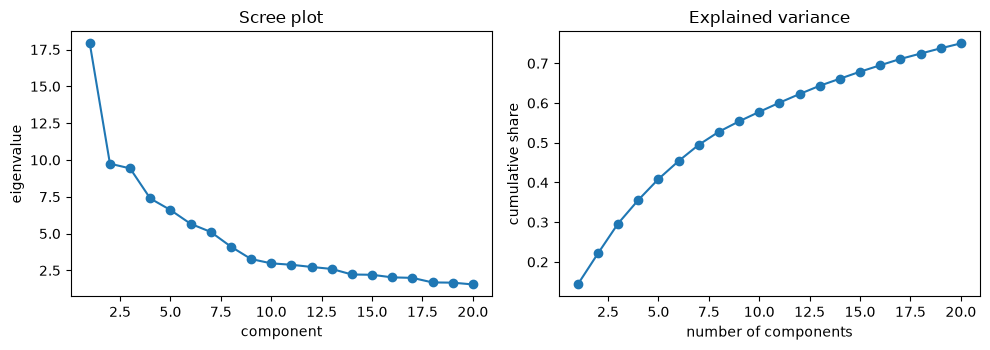

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(range(1, 21), eigval[:20], "o-")
ax[0].set_xlabel("component"); ax[0].set_ylabel("eigenvalue"); ax[0].set_title("Scree plot")
ax[1].plot(range(1, 21), share[:20].cumsum(), "o-")
ax[1].set_xlabel("number of components"); ax[1].set_ylabel("cumulative share"); ax[1].set_title("Explained variance")
plt.tight_layout()
plt.savefig(RESULTS / "scree_plot.png", dpi=150)
plt.show()

In [10]:
kmax = 10
rows = []
for k in range(kmax + 1):
    V = eigval[k:].sum() / N      # average squared residual with k factors
    c = (N + T) / (N * T)
    rows.append((k,
                 np.log(V) + k * c * np.log(N * T / (N + T)),
                 np.log(V) + k * c * np.log(min(N, T)),
                 np.log(V) + k * np.log(min(N, T)) / min(N, T)))
ic = pd.DataFrame(rows, columns=["k", "IC1", "IC2", "IC3"]).set_index("k")
print(ic.round(3).T)
print("selected k:", ic.idxmin().to_dict())

k     0      1      2      3      4      5      6      7      8      9      10
IC1  0.0 -0.096 -0.134 -0.177 -0.207 -0.234 -0.255 -0.275 -0.284 -0.283 -0.279
IC2  0.0 -0.089 -0.119 -0.156 -0.178 -0.198 -0.212 -0.225 -0.227 -0.218 -0.208
IC3  0.0 -0.116 -0.173 -0.236 -0.285 -0.332 -0.373 -0.413 -0.441 -0.460 -0.476
selected k: {'IC1': 8, 'IC2': 8, 'IC3': 10}


## Forecasting

## Evaluation

## Results

In [7]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 17.4 MB/s  0:00:00 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 15.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 13.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
